# 04 — ML Classification Benchmark & Model Selection

**Objective:** Train and compare four supervised classification algorithms (`Logistic Regression`, `SVM`, `Decision Tree`, `KNN`) using a leakage-free Scikit-Learn `Pipeline` (`StandardScaler` + `OneHotEncoder`) and 5-fold `GridSearchCV`, then serialize the top-performing model to `models/best_churn_model.pkl`.

In [1]:
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.train_model import train_and_benchmark

ASSETS_DIR = PROJECT_ROOT / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Run Leakage-Free 5-Fold `GridSearchCV` Benchmark

In [2]:
summary = train_and_benchmark()
results_df = summary["results_df"]
display(results_df[["Model", "CV ROC-AUC", "Test Accuracy", "Test F1", "Test ROC-AUC", "Best Params"]])
print(f"Winning model: {summary['winner_name']} -> {summary['model_path']}")

C:\Users\danis\OneDrive\Desktop\Project\InsurAI Policyholder Retention & Risk Analytics Pipeline\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,CV ROC-AUC,Test Accuracy,Test F1,Test ROC-AUC,Best Params
0,SVM,0.7111,0.7267,0.2407,0.6852,"{'classifier__C': 0.5, 'classifier__kernel': '..."
1,Logistic Regression,0.7143,0.7367,0.3780,0.6810,{'classifier__C': 10.0}
2,KNN,0.6431,0.7067,0.2414,0.6645,{'classifier__n_neighbors': 11}
3,Decision Tree,0.6709,0.7233,0.3025,0.6572,"{'classifier__criterion': 'entropy', 'classifi..."


Winning model: SVM -> C:\Users\danis\OneDrive\Desktop\Project\InsurAI Policyholder Retention & Risk Analytics Pipeline\models\best_churn_model.pkl


## 2. ROC Curves & Confusion Matrices on Held-Out Test Set (20%)

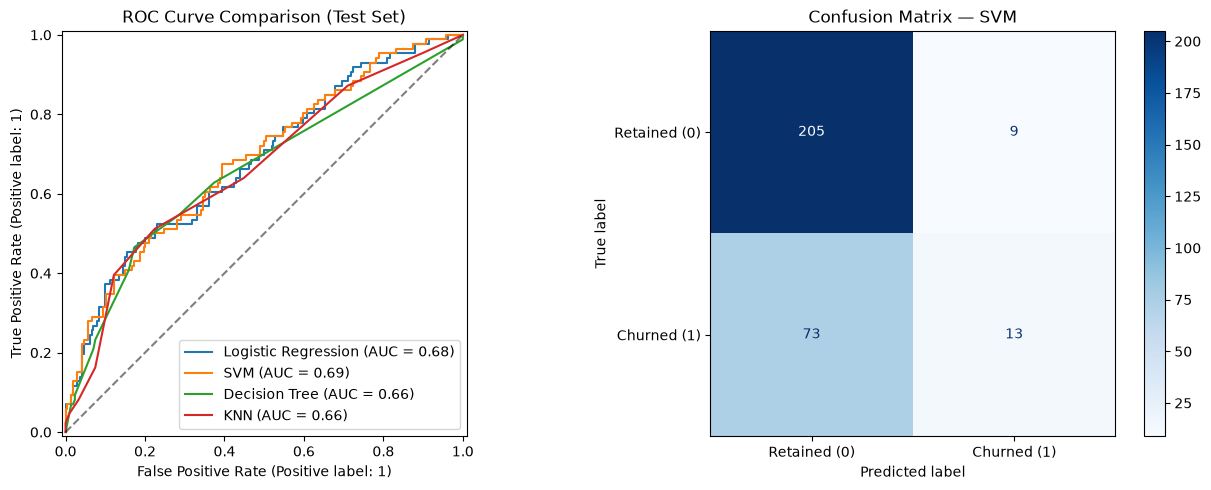

In [3]:
X_test = summary["X_test"]
y_test = summary["y_test"]
fitted_models = summary["fitted_models"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC Curve Comparison (Test Set)")

winner_name = summary["winner_name"]
ConfusionMatrixDisplay.from_estimator(
    fitted_models[winner_name],
    X_test,
    y_test,
    ax=axes[1],
    cmap="Blues",
    display_labels=["Retained (0)", "Churned (1)"],
)
axes[1].set_title(f"Confusion Matrix — {winner_name}")

plt.tight_layout()
plt.savefig(ASSETS_DIR / "ml_model_comparison.png", dpi=150)
plt.show()

## 3. Verify Serialized Pipeline (`best_churn_model.pkl`)

In [4]:
loaded_model = joblib.load(summary["model_path"])
sample = pd.DataFrame([
    {
        "age": 34,
        "tenure_months": 8,
        "monthly_premium_rm": 420.0,
        "annual_value_rm": 5040.0,
        "claims_count": 1,
        "late_payments": 3,
        "support_tickets": 4,
        "region": "Kuala Lumpur",
        "policy_type": "Investment-Linked",
    }
])
prob = loaded_model.predict_proba(sample)[0, 1]
print(f"Sample high-risk profile churn probability: {prob * 100:.2f}%")

Sample high-risk profile churn probability: 90.10%


## Key Insights

- **Leakage Prevention:** `StandardScaler` and `OneHotEncoder` are encapsulated inside a Scikit-Learn `Pipeline`, ensuring preprocessing parameters are learned strictly from each training fold. `policy_id` and `churn_reason` are excluded from `X`.
- **Metric Selection:** Models are ranked on **ROC-AUC** and **F1-Score** rather than Accuracy alone, ensuring balanced detection of minority-class churners.
- **Deployment Readiness:** The winning pipeline is serialized to `models/best_churn_model.pkl` and accepts raw feature dictionaries directly for the Streamlit live risk simulator.